# Multi-pulse ion-electron(-photon) entanglement

This notebook is the **interactive run and analysis layer**. Reusable physics, grid construction, entanglement measures, spontaneous-emission amplitudes, and plotting functions live in the accompanying `.py` modules.

The intended workflow is:

1. define the physical parameters and pulse sequence;
2. inspect the field and driven dynamics;
3. calculate photoelectron spectra and ion-electron entanglement;
4. run parameter scans;
5. optionally include spontaneous emission and ion-electron-photon entanglement.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import timeit

import numpy as np
import matplotlib.pyplot as plt

# Make imports work whether Jupyter was opened from the repository root or
# from the multipulse/ directory.
cwd = Path.cwd()
repo_root = cwd.parent if cwd.name == "multipulse" else cwd
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common import general_functions as gf
from common.entanglement import entanglement_ab, entanglement_abcd
from multipulse.energy_grids import def_eps, def_eps_l
from multipulse.functions import def_t_array, calc_field, WF_amp_Npulse
from multipulse.plotting import (
    plot_field,
    plot_rabi_populations,
    plot_photoelectron_spectra,
    plot_spontaneous_spectra,
    plot_scan_results,
)
from multipulse.spontaneous_emission import WF_amp_spontaneous_Npulse


## 1. System parameters and pulse sequence


In [2]:
# System parameters
omega_0 = 1.5                   # Carrier / resonant transition energy (a.u.)
eps_ba = 1.5                    # Ionic transition energy (a.u.)
z0 = 0.502                      # Ionisation dipole matrix element
z12 = 0.37323                   # Bound-bound dipole matrix element

# Peak field
I0 = 1.246759e13                # W/cm^2
E0 = gf.I_to_E0(I0)             # a.u.
Omega = z12 * E0                # Rabi frequency (a.u.)

# Pulse type: 'gaus' or 'ftop'
typ = 'gaus'

# Duration corresponding to a 2pi pulse area
if typ == 'ftop':
    tau_2pi = 2 * np.pi / (E0 * z12)
else:
    tau_2pi = 2 * np.pi / (E0 * z12) * np.sqrt(np.log(4) / np.pi)

tau = 2.5 * tau_2pi

# Pulse centres in units of half carrier cycles.
# even integer -> in phase; odd integer -> opposite phase.
field_half_cycle = np.pi / omega_0
Is = np.array([0])

t_Is = field_half_cycle * Is
EI = E0 * np.ones(len(Is))
tau_I = tau * np.ones(len(Is))

# Numerical grids
t = def_t_array(typ, t_Is, tau_I)
eps = def_eps(tau_I, t_Is, eps_ba, typ, Omega, adaptive=True)


## 2. Electric field


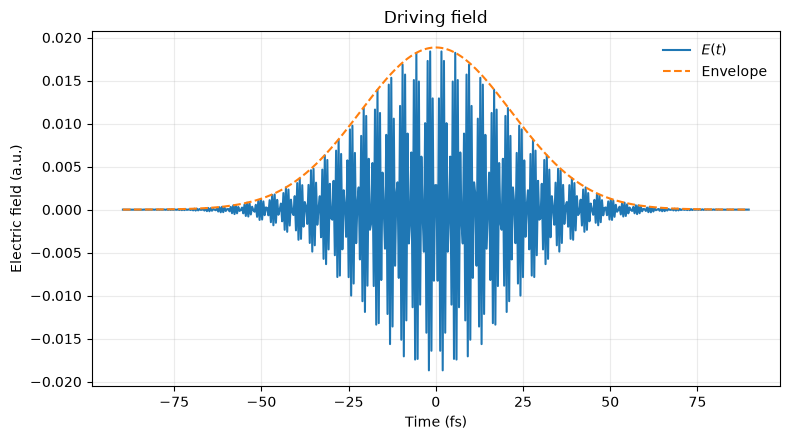

In [3]:
Et, E_Envelope, Envelope_I, E_pos = calc_field(
    t, t_Is, EI, tau_I, omega_0, typ
)

plot_field(
    t,
    Et,
    E_Envelope,
    time_scale=gf.AU_TIME*1e-3,
    time_label="Time (fs)",
)
plt.show()


## 3. Driven amplitudes and depletion


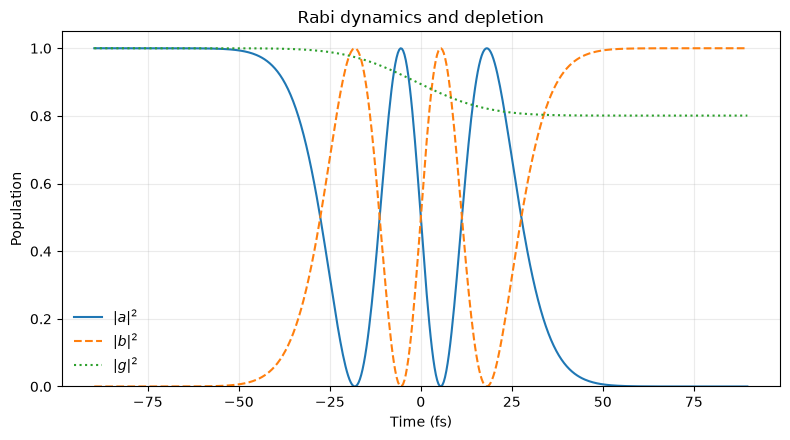

In [4]:
a, b, g, c_a, c_b = WF_amp_Npulse(
    t=t,
    eps=eps,
    t_Is=t_Is,
    EI=EI,
    tau_I=tau_I,
    omega_0=omega_0,
    z12=z12,
    z0=z0,
    typ=typ,
    depletion=True,
)

plot_rabi_populations(
    t,
    a,
    b,
    g,
    time_scale=gf.AU_TIME*1e-3,
    time_label="Time (fs)",
)
plt.show()


## 4. Photoelectron spectra


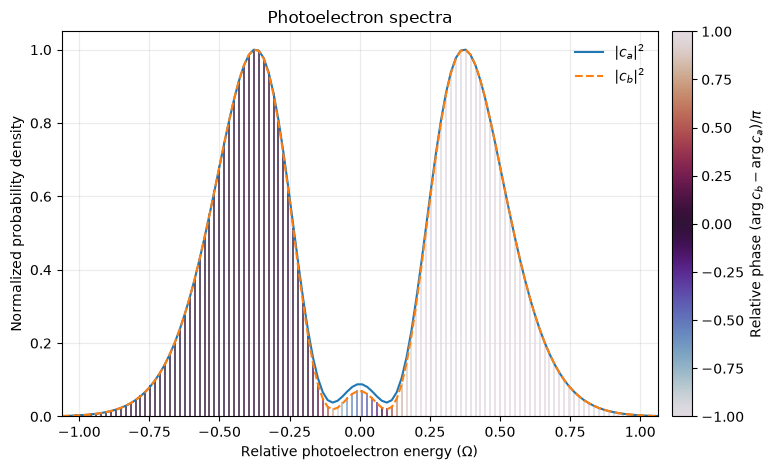

In [5]:
plot_photoelectron_spectra(
    eps,
    c_a,
    c_b,
    energy_scale= (np.max(EI)*z12)**-1,
    energy_label=r"Relative photoelectron energy ($\Omega$)",
)
plt.show()


## 5. Ion-electron entanglement


In [6]:
S_ab = entanglement_ab(eps, c_a, c_b)
print(f"Ion-electron entanglement entropy: {S_ab:.6f} bits")


Ion-electron entanglement entropy: 0.999650 bits


## 6. Example: single-pulse duration scan

This scan varies the duration of the first pulse while keeping its centre and peak field fixed. The adaptive electron-energy grid is rebuilt at each duration.


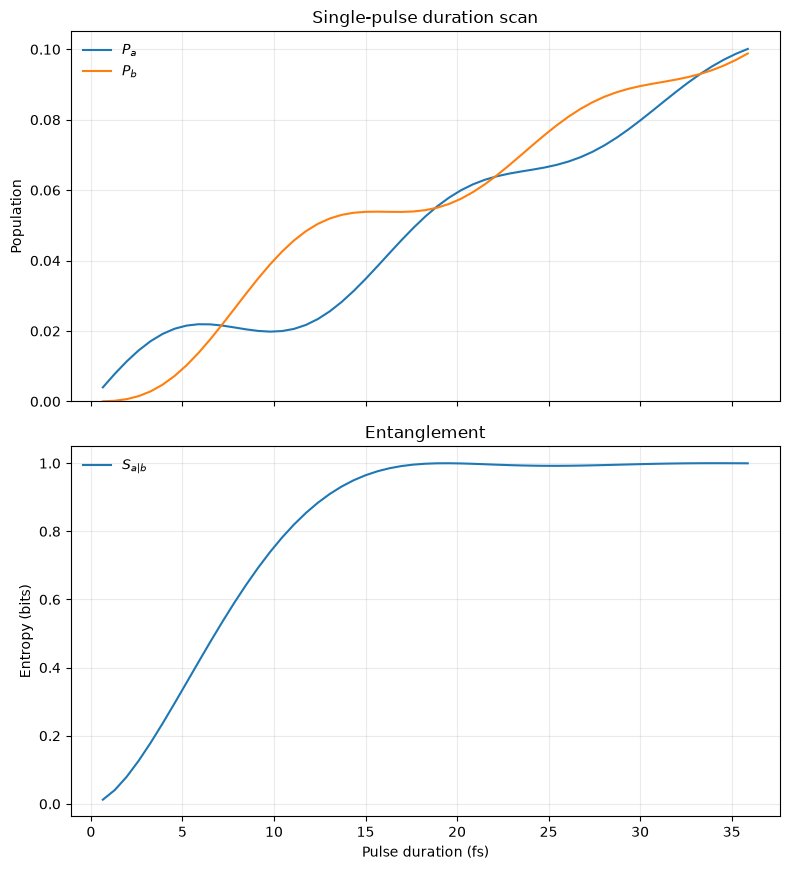

In [7]:
tau_scan = np.linspace(0, tau_I[0], 56)[1:]

SvN_scan = np.zeros(len(tau_scan))
P_a_scan = np.zeros(len(tau_scan))
P_b_scan = np.zeros(len(tau_scan))

for i, tau_value in enumerate(tau_scan):
    tau_current = np.array([tau_value])
    t_current = def_t_array(typ, t_Is[:1], tau_current)
    eps_current = def_eps(
        tau_current,
        t_Is[:1],
        eps_ba,
        typ,
        abs(EI[0] * z12),
        adaptive=True,
    )

    _, _, _, c_a_current, c_b_current = WF_amp_Npulse(
        t=t_current,
        eps=eps_current,
        t_Is=t_Is[:1],
        EI=EI[:1],
        tau_I=tau_current,
        omega_0=omega_0,
        z12=z12,
        z0=z0,
        typ=typ,
        depletion=True,
    )

    P_a_scan[i] = np.trapezoid(np.abs(c_a_current) ** 2, x=eps_current)
    P_b_scan[i] = np.trapezoid(np.abs(c_b_current) ** 2, x=eps_current)
    SvN_scan[i] = entanglement_ab(eps_current, c_a_current, c_b_current)

plot_scan_results(
    tau_scan * gf.AU_TIME*1e-3,
    populations={r"$P_a$": P_a_scan, r"$P_b$": P_b_scan},
    entropies={r"$S_{a|b}$": SvN_scan},
    x_label="Pulse duration (fs)",
    title="Single-pulse duration scan",
)
plt.show()


## 7. Example: two-pulse sequence scan

For a two-pulse sequence this example follows three stages: growth of pulse 1, the field-free delay, and growth of pulse 2. It is skipped automatically for other pulse counts.


In [8]:
if len(tau_I) == 2:
    tau0_scan = np.linspace(0, tau_I[0], 56)[1:]
    delay_scan = np.linspace(tau_I[0] * 2.5, t_Is[1] - tau_I[1] * 2.5, 25)[1:]
    tau1_scan = np.linspace(0, tau_I[1], 56)[1:]

    total_scan = np.concatenate((tau0_scan, delay_scan, tau1_scan + t_Is[1]))
    SvN_two = np.zeros(len(total_scan))
    P_a_two = np.zeros(len(total_scan))
    P_b_two = np.zeros(len(total_scan))

    cursor = 0

    # Stage 1: grow the first pulse.
    for tau_value in tau0_scan:
        widths = np.array([tau_value])
        centres = t_Is[:1]
        fields = EI[:1]
        t_current = def_t_array(typ, centres, widths)
        eps_current = def_eps(widths, centres, eps_ba, typ, abs(fields[0] * z12))
        _, _, _, ca, cb = WF_amp_Npulse(
            t_current, eps_current, centres, fields, widths,
            omega_0, z12, z0, typ, depletion=True,
        )
        P_a_two[cursor] = np.trapezoid(np.abs(ca) ** 2, x=eps_current)
        P_b_two[cursor] = np.trapezoid(np.abs(cb) ** 2, x=eps_current)
        SvN_two[cursor] = entanglement_ab(eps_current, ca, cb)
        cursor += 1

    # Stage 2: increase the delay before a vanishingly short second pulse.
    for delay_value in delay_scan:
        widths = np.array([tau_I[0], 1e-10])
        centres = np.array([t_Is[0], delay_value])
        t_current = def_t_array(typ, centres, widths)
        eps_current = def_eps(
            tau_I[:1], t_Is[:1], eps_ba, typ, abs(EI[0] * z12)
        )
        _, _, _, ca, cb = WF_amp_Npulse(
            t_current, eps_current, centres, EI, widths,
            omega_0, z12, z0, typ, depletion=True,
        )
        P_a_two[cursor] = np.trapezoid(np.abs(ca) ** 2, x=eps_current)
        P_b_two[cursor] = np.trapezoid(np.abs(cb) ** 2, x=eps_current)
        SvN_two[cursor] = entanglement_ab(eps_current, ca, cb)
        cursor += 1

    # Stage 3: grow the second pulse at its final centre time.
    for tau_value in tau1_scan:
        widths = np.array([tau_I[0], tau_value])
        t_current = def_t_array(typ, t_Is, widths)
        eps_current = def_eps(widths, t_Is, eps_ba, typ, np.max(np.abs(EI)) * abs(z12))
        _, _, _, ca, cb = WF_amp_Npulse(
            t_current, eps_current, t_Is, EI, widths,
            omega_0, z12, z0, typ, depletion=True,
        )
        P_a_two[cursor] = np.trapezoid(np.abs(ca) ** 2, x=eps_current)
        P_b_two[cursor] = np.trapezoid(np.abs(cb) ** 2, x=eps_current)
        SvN_two[cursor] = entanglement_ab(eps_current, ca, cb)
        cursor += 1

    plot_scan_results(
        total_scan * gf.AU_TIME*1e-3,
        populations={r"$P_a$": P_a_two, r"$P_b$": P_b_two},
        entropies={r"$S_{a|b}$": SvN_two},
        x_label="Sequence time (fs)",
        title="Two-pulse sequence scan",
    )
    plt.show()
else:
    print("Two-pulse scan skipped: define exactly two pulses to run this example.")


Two-pulse scan skipped: define exactly two pulses to run this example.


## 8. Spontaneous emission after the pulse

The photon grid is adaptive. `include_secondary=True` adds a graded outer grid to capture side peaks without introducing a large spacing jump at the edge of the dense central grid.


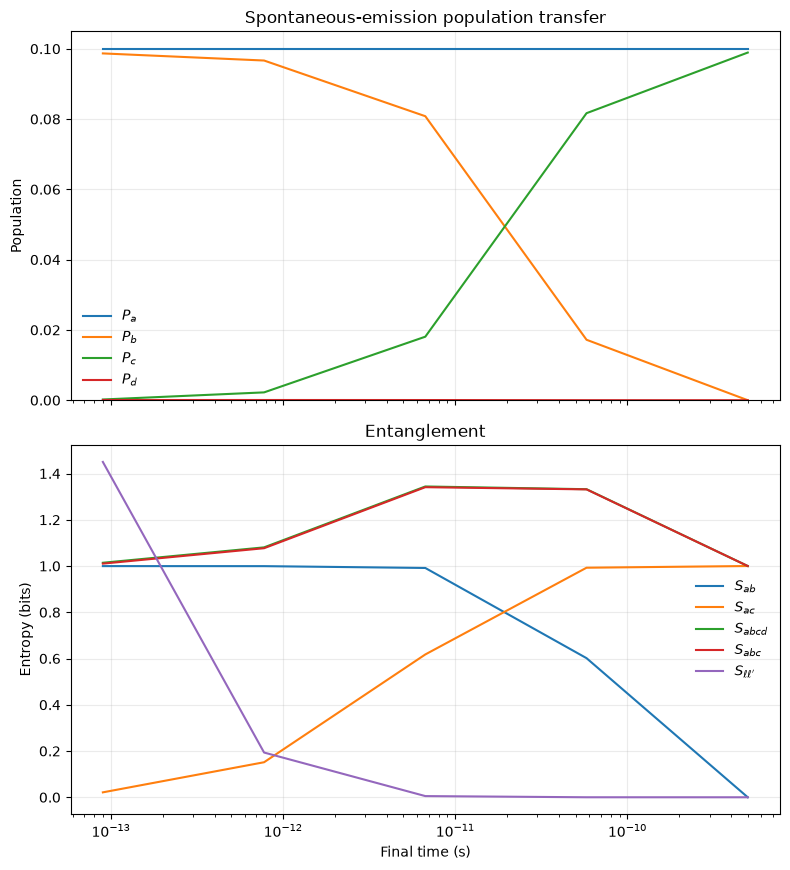

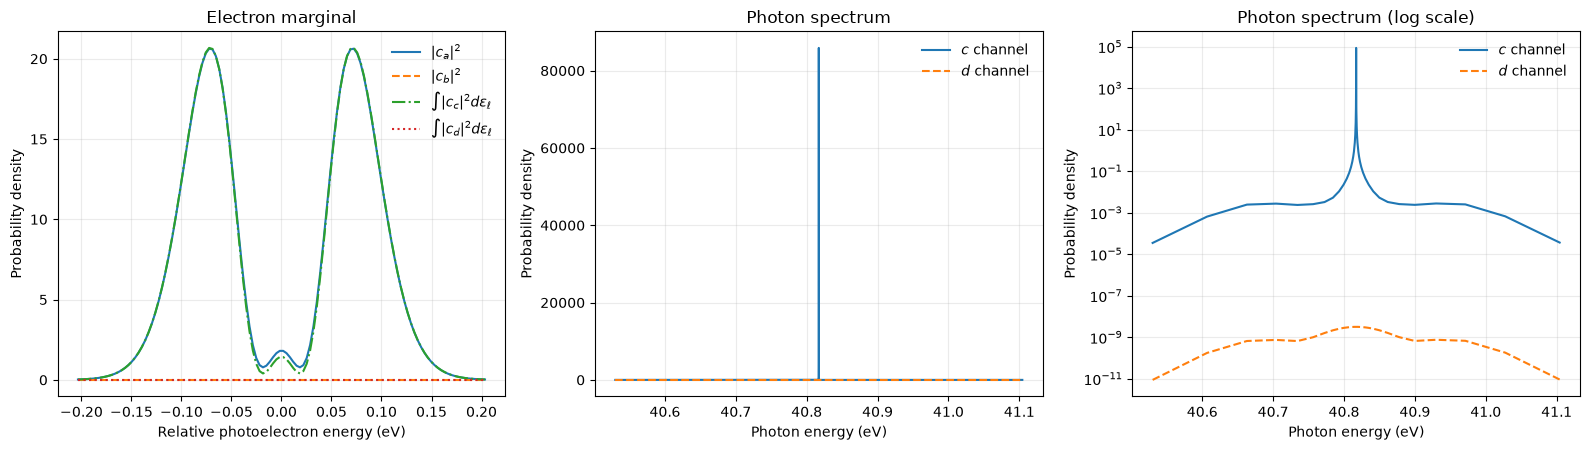

Initial P_b = 0.0986819; final P_c = 0.0989227
Runtime: 13.42 s


In [9]:
start_time = timeit.default_timer()

tf_pulse_end = t[-1]
tf_max = 5e8 / gf.AU_TIME

tf_array = np.geomspace(tf_pulse_end, tf_max, 5)

P_a = np.zeros(len(tf_array))
P_b = np.zeros(len(tf_array))
P_c = np.zeros(len(tf_array))
P_d = np.zeros(len(tf_array))

ent_ab = np.zeros(len(tf_array))
ent_ac = np.zeros(len(tf_array))
ent_abcd = np.zeros(len(tf_array))
ent_abc = np.zeros(len(tf_array))
ent_ll = np.zeros(len(tf_array))

for i, tf in enumerate(tf_array):
    eps_l = def_eps_l(
        tf,
        t,
        EI,
        z12,
        eps_ba,
        Nl=111,
        adaptive=True,
        include_secondary=True,
        Nl2=100,
    )

    a, b, g, c_a, c_b, c_c, c_d = WF_amp_spontaneous_Npulse(
        tf=tf,
        t=t,
        eps=eps,
        eps_l=eps_l,
        t_Is=t_Is,
        EI=EI,
        tau_I=tau_I,
        omega_0=omega_0,
        eps_ba=eps_ba,
        z12=z12,
        z0=z0,
        typ=typ,
        depletion=True,
    )

    ent_ab[i], ent_ac[i], ent_abcd[i], ent_abc[i], ent_ll[i] = entanglement_abcd(
        eps, eps_l, c_a, c_b, c_c, c_d
    )

    P_a[i] = np.trapezoid(np.abs(c_a) ** 2, x=eps)
    P_b[i] = np.trapezoid(np.abs(c_b) ** 2, x=eps)
    P_c[i] = np.trapezoid(np.trapezoid(np.abs(c_c) ** 2, x=eps_l, axis=1), x=eps)
    P_d[i] = np.trapezoid(np.trapezoid(np.abs(c_d) ** 2, x=eps_l, axis=1), x=eps)

plot_scan_results(
    tf_array * gf.AU_TIME*1e-18,
    populations={r"$P_a$": P_a, r"$P_b$": P_b, r"$P_c$": P_c, r"$P_d$": P_d},
    entropies={
        r"$S_{ab}$": ent_ab,
        r"$S_{ac}$": ent_ac,
        r"$S_{abcd}$": ent_abcd,
        r"$S_{abc}$": ent_abc,
        r"$S_{\ell\ell'}$": ent_ll,
    },
    x_label="Final time (s)",
    log_x=True,
    title="Spontaneous-emission population transfer",
)
plt.show()

# Inspect the final spectra.
plot_spontaneous_spectra(
    eps,
    eps_l,
    c_a,
    c_b,
    c_c,
    c_d,
    electron_scale=gf.AU_ENERGY,
    photon_scale=gf.AU_ENERGY,
    electron_label="Relative photoelectron energy (eV)",
    photon_label="Photon energy (eV)",
)
plt.show()

print(f"Initial P_b = {P_b[0]:.6g}; final P_c = {P_c[-1]:.6g}")
print(f"Runtime: {timeit.default_timer() - start_time:.2f} s")


## 9. Example: pulse-duration plus post-pulse scan

The first part scans the pulse duration up to the selected pulse, then the second part follows the field-free spontaneous-emission dynamics after the pulse.


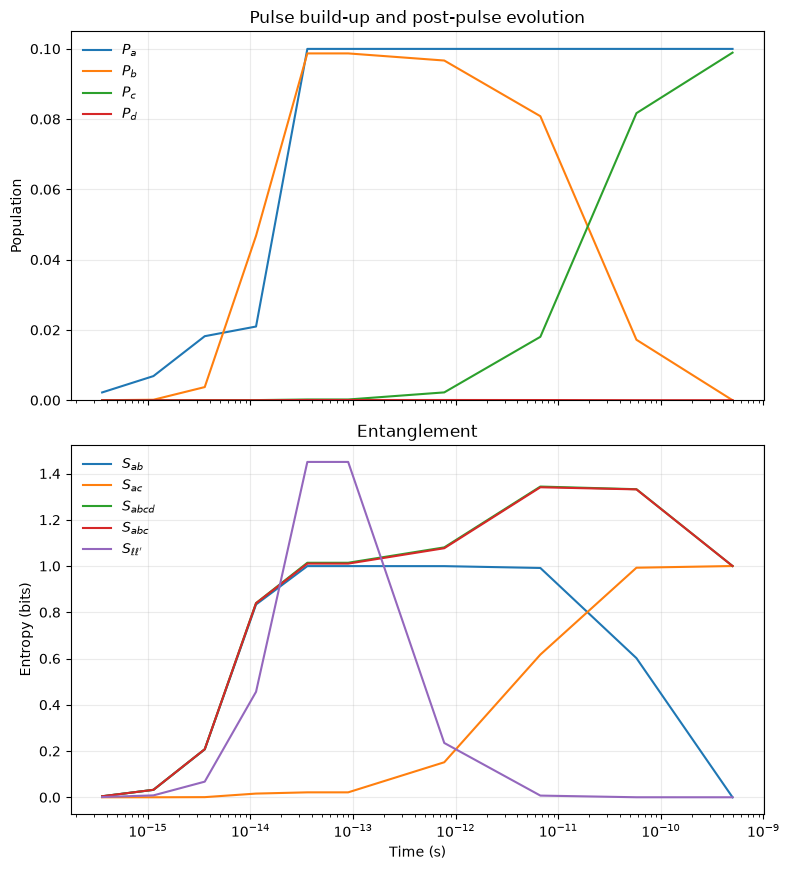

In [10]:
tau_scan = np.geomspace(tau_I[0] / 100, tau_I[0], 5)
tf_array = np.geomspace(tf_pulse_end, tf_max, 5)
total_scan = np.concatenate((tau_scan, tf_array))

P_a_combined = np.zeros(len(total_scan))
P_b_combined = np.zeros(len(total_scan))
P_c_combined = np.zeros(len(total_scan))
P_d_combined = np.zeros(len(total_scan))

ent_ab_combined = np.zeros(len(total_scan))
ent_ac_combined = np.zeros(len(total_scan))
ent_abcd_combined = np.zeros(len(total_scan))
ent_abc_combined = np.zeros(len(total_scan))
ent_ll_combined = np.zeros(len(total_scan))

# During pulse build-up.
for i, tau_value in enumerate(tau_scan):
    widths = np.array([tau_value])
    centres = t_Is[:1]
    fields = EI[:1]
    t_current = def_t_array(typ, centres, widths)
    eps_current = def_eps(widths, centres, eps_ba, typ, abs(fields[0] * z12))
    eps_l_current = def_eps_l(
        t_current[-1], t_current, fields, z12, eps_ba, Nl=111
    )

    _, _, _, ca, cb, cc, cd = WF_amp_spontaneous_Npulse(
        t_current[-1], t_current, eps_current, eps_l_current,
        centres, fields, widths, omega_0, eps_ba, z12, z0, typ,
        depletion=True,
    )

    ent_ab_combined[i], ent_ac_combined[i], ent_abcd_combined[i], ent_abc_combined[i], ent_ll_combined[i] = entanglement_abcd(
        eps_current, eps_l_current, ca, cb, cc, cd
    )
    P_a_combined[i] = np.trapezoid(np.abs(ca) ** 2, x=eps_current)
    P_b_combined[i] = np.trapezoid(np.abs(cb) ** 2, x=eps_current)
    P_c_combined[i] = np.trapezoid(np.trapezoid(np.abs(cc) ** 2, x=eps_l_current, axis=1), x=eps_current)
    P_d_combined[i] = np.trapezoid(np.trapezoid(np.abs(cd) ** 2, x=eps_l_current, axis=1), x=eps_current)

# Re-establish the full selected pulse before the post-pulse scan.
t_post = def_t_array(typ, t_Is[:1], tau_I[:1])
eps_post = def_eps(tau_I[:1], t_Is[:1], eps_ba, typ, abs(EI[0] * z12))

for j, tf in enumerate(tf_array):
    idx = len(tau_scan) + j
    eps_l_current = def_eps_l(
        tf,
        t_post,
        EI[:1],
        z12,
        eps_ba,
        Nl=111,
        include_secondary=True,
        Nl2=100,
    )

    _, _, _, ca, cb, cc, cd = WF_amp_spontaneous_Npulse(
        tf, t_post, eps_post, eps_l_current,
        t_Is[:1], EI[:1], tau_I[:1], omega_0, eps_ba, z12, z0, typ,
        depletion=True,
    )

    ent_ab_combined[idx], ent_ac_combined[idx], ent_abcd_combined[idx], ent_abc_combined[idx], ent_ll_combined[idx] = entanglement_abcd(
        eps_post, eps_l_current, ca, cb, cc, cd
    )
    P_a_combined[idx] = np.trapezoid(np.abs(ca) ** 2, x=eps_post)
    P_b_combined[idx] = np.trapezoid(np.abs(cb) ** 2, x=eps_post)
    P_c_combined[idx] = np.trapezoid(np.trapezoid(np.abs(cc) ** 2, x=eps_l_current, axis=1), x=eps_post)
    P_d_combined[idx] = np.trapezoid(np.trapezoid(np.abs(cd) ** 2, x=eps_l_current, axis=1), x=eps_post)

plot_scan_results(
    total_scan * gf.AU_TIME * 1e-18,
    populations={
        r"$P_a$": P_a_combined,
        r"$P_b$": P_b_combined,
        r"$P_c$": P_c_combined,
        r"$P_d$": P_d_combined,
    },
    entropies={
        r"$S_{ab}$": ent_ab_combined,
        r"$S_{ac}$": ent_ac_combined,
        r"$S_{abcd}$": ent_abcd_combined,
        r"$S_{abc}$": ent_abc_combined,
        r"$S_{\ell\ell'}$": ent_ll_combined,
    },
    x_label="Time (s)",
    log_x=True,
    title="Pulse build-up and post-pulse evolution",
)
plt.show()
